In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib requests python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import requests

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
file_path = r"C:\Users\krish\Downloads\archive (7)\air_quality_dataset.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Dataset shape: (5583, 11)


,Date,City,AQI,PM2.5,PM10,Ozone,NO2,CO,SO2,Temperature,Humidity
0,2024-10-16,Los Angeles,128.0,28.78,68.84,58.29,57.56,2.781,17.10,3.4,82.2
1,2023-01-26,Jacksonville,111.0,28.73,61.93,59.00,35.73,1.810,16.33,17.0,36.0
2,2023-10-09,Houston,91.0,20.04,47.10,66.20,43.91,2.566,15.27,1.0,68.6
3,2023-08-17,Chicago,108.0,23.39,47.90,62.85,48.89,2.332,18.49,9.4,85.7
4,2023-04-15,Austin,106.0,26.51,56.08,62.38,NaN,1.867,15.93,17.3,48.7


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5583 entries, 0 to 5582
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Date         5583 non-null   object 
 1   City         5583 non-null   object 
 2   AQI          5472 non-null   float64
 3   PM2.5        5486 non-null   float64
 4   PM10         5523 non-null   float64
 5   Ozone        5508 non-null   float64
 6   NO2          5490 non-null   float64
 7   CO           5421 non-null   float64
 8   SO2          5454 non-null   float64
 9   Temperature  5435 non-null   float64
 10  Humidity     5479 non-null   float64
dtypes: float64(9), object(2)
memory usage: 479.9+ KB


None

In [32]:
df['City'].unique()

array(['San Jose', 'Fort Worth', 'Columbus', 'Chicago', 'Jacksonville',
       'Phoenix', 'Philadelphia', 'Charlotte', 'Houston', 'Dallas',
       'Austin', 'New York', 'San Antonio', 'San Diego', 'Los Angeles'],
      dtype=object)

In [4]:
file_path = r"C:\Users\krish\Downloads\air_quality_dataset(1).csv"

In [5]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumber of cities:", df["City"].nunique())

print("\nAQI summary:")
display(df["AQI"].describe())

Shape: (5583, 11)

Column names:
['Date', 'City', 'AQI', 'PM2.5', 'PM10', 'Ozone', 'NO2', 'CO', 'SO2', 'Temperature', 'Humidity']

Data types:
Date            object
City            object
AQI            float64
PM2.5          float64
PM10           float64
Ozone          float64
NO2            float64
CO             float64
SO2            float64
Temperature    float64
Humidity       float64
dtype: object

Missing values:
Date             0
City             0
AQI            111
PM2.5           97
PM10            60
Ozone           75
NO2             93
CO             162
SO2            129
Temperature    148
Humidity       104
dtype: int64

Duplicate rows: 86

Number of cities: 15

AQI summary:


count    5472.000000
mean      111.969664
std        24.152583
min        46.000000
25%        96.000000
50%       110.000000
75%       126.000000
max       497.000000
Name: AQI, dtype: float64

In [6]:
df = df.copy()

# Convert date to datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Remove duplicate records
df = df.drop_duplicates()

# Remove invalid dates
df = df.dropna(subset=["Date"])

# Rows without a target AQI cannot train a supervised regressor
df = df.dropna(subset=["AQI"])

# Keep plausible non-negative AQI targets
df = df[df["AQI"] >= 0]

df = df.sort_values("Date").reset_index(drop=True)

print("Shape after cleaning:", df.shape)
print("\nRemaining missing values:")
print(df.isnull().sum())

Shape after cleaning: (5387, 11)

Remaining missing values:
Date             0
City             0
AQI              0
PM2.5           97
PM10            59
Ozone           72
NO2             91
CO             158
SO2            122
Temperature    142
Humidity       102
dtype: int64


In [7]:
# Fill missing numerical values using each city's median
numeric_cols = [
    'PM2.5', 'PM10', 'Ozone', 'NO2',
    'CO', 'SO2', 'Temperature', 'Humidity'
]

for col in numeric_cols:
    df[col] = df.groupby('City')[col].transform(
        lambda x: x.fillna(x.median())
    )

# If any null values remain (e.g., an entire city column is missing),
# fill them using the overall column median
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Verify
print("Shape after cleaning:", df.shape)
print("\nRemaining missing values:")
print(df.isnull().sum())

Shape after cleaning: (5387, 11)

Remaining missing values:
Date           0
City           0
AQI            0
PM2.5          0
PM10           0
Ozone          0
NO2            0
CO             0
SO2            0
Temperature    0
Humidity       0
dtype: int64


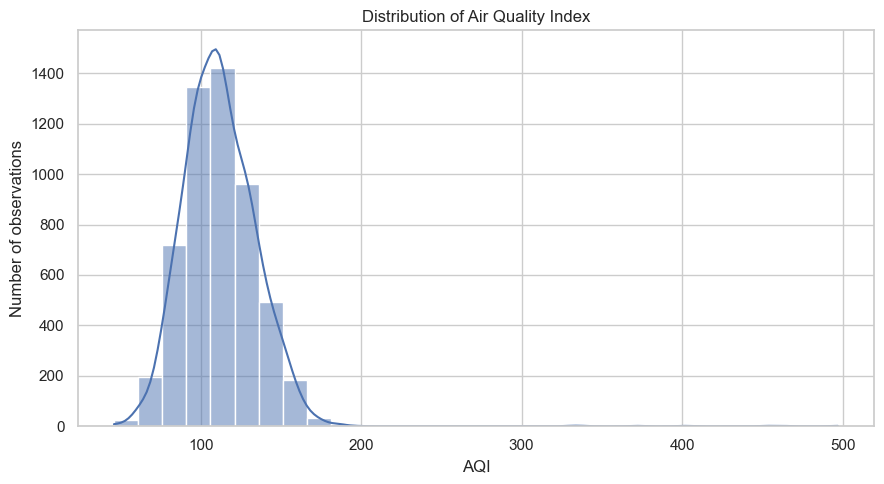

In [8]:
plt.figure(figsize=(9, 5))
sns.histplot(df["AQI"], bins=30, kde=True)

plt.title("Distribution of Air Quality Index")
plt.xlabel("AQI")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

In [9]:
# missing = df.isnull().sum()
# missing = missing[missing > 0].sort_values(ascending=False)

# plt.figure(figsize=(9, 5))
# missing.plot(kind="bar")

# plt.title("Missing Values by Column")
# plt.xlabel("Feature")
# plt.ylabel("Missing count")
# plt.xticks(rotation=45)
# plt.tight_layout()
# plt.show()

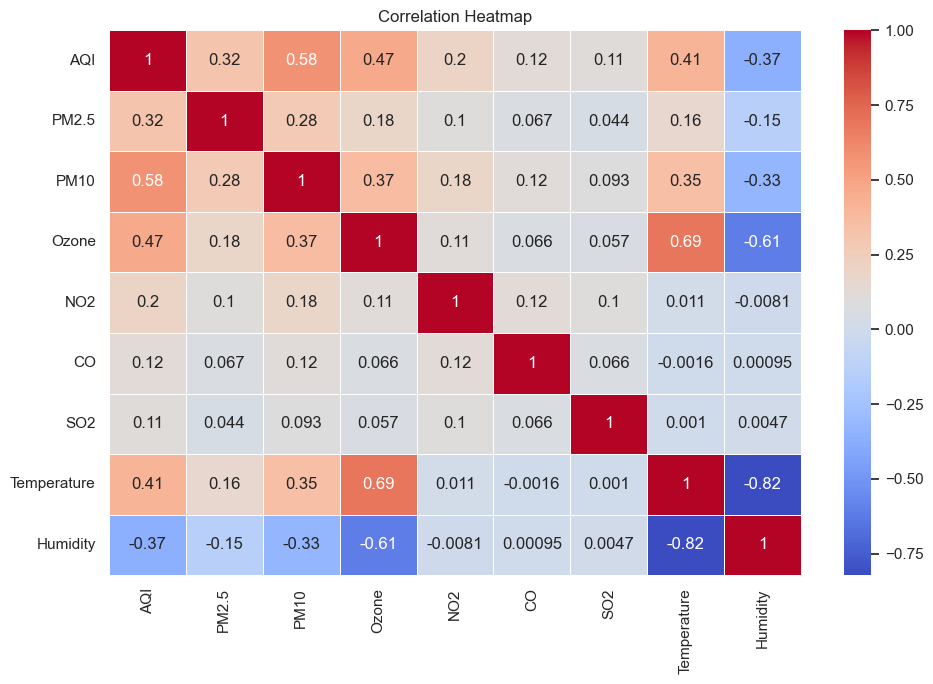

In [10]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    # fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

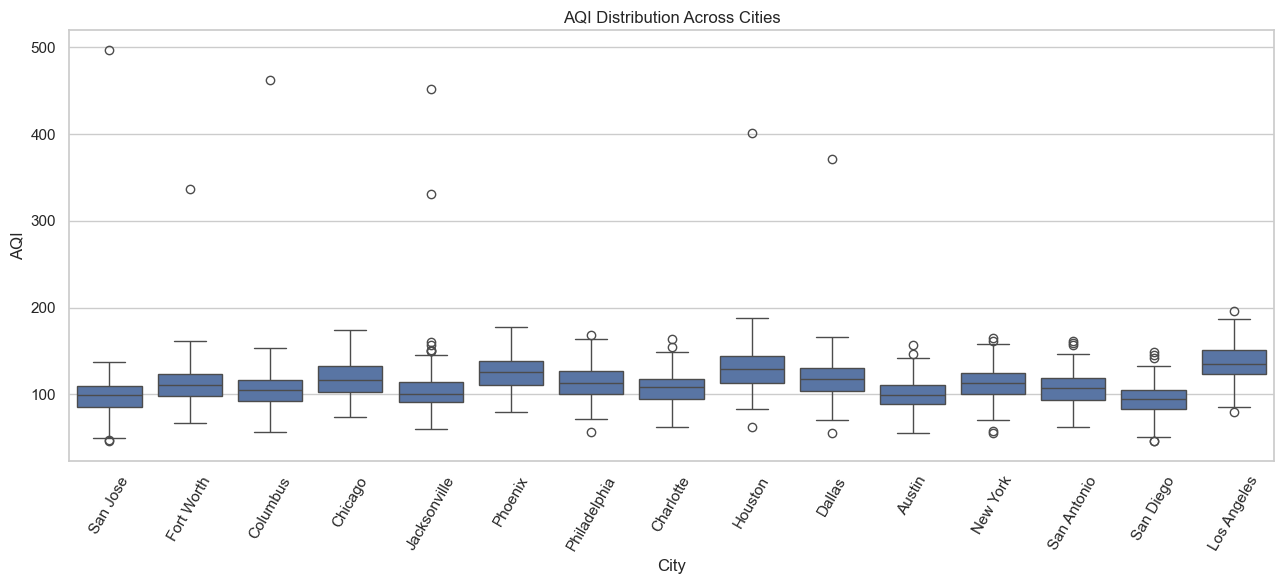

In [11]:
plt.figure(figsize=(13, 6))

sns.boxplot(
    data=df,
    x="City",
    y="AQI"
)

plt.title("AQI Distribution Across Cities")
plt.xlabel("City")
plt.ylabel("AQI")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

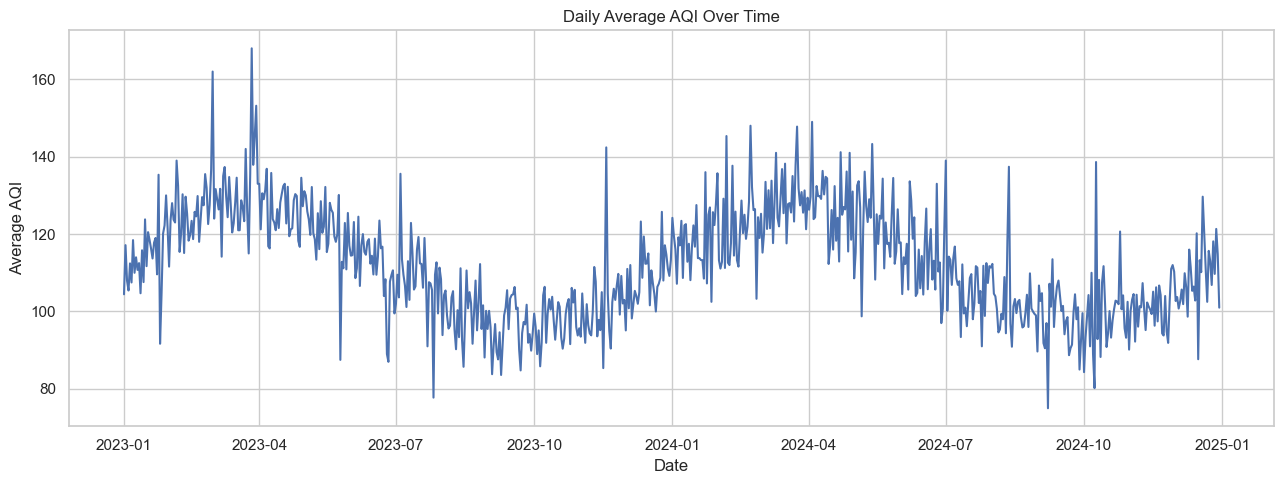

In [12]:
daily_aqi = (
    df.groupby("Date")["AQI"]
      .mean()
      .sort_index()
)

plt.figure(figsize=(13, 5))
plt.plot(daily_aqi.index, daily_aqi.values)

plt.title("Daily Average AQI Over Time")
plt.xlabel("Date")
plt.ylabel("Average AQI")
plt.tight_layout()
plt.show()

In [13]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["DayOfWeek"] = df["Date"].dt.dayofweek

# Target
X = df.drop(columns=["AQI", "Date"])
y = df["AQI"]

numeric_features = [
    "PM2.5",
    "PM10",
    "Ozone",
    "NO2",
    "CO",
    "SO2",
    "Temperature",
    "Humidity",
    "Year",
    "Month",
    "Day",
    "DayOfWeek"
]

categorical_features = ["City"]

print("Input features:", X.columns.tolist())
print("Target:", "AQI")
print("Number of rows:", len(X))

Input features: ['City', 'PM2.5', 'PM10', 'Ozone', 'NO2', 'CO', 'SO2', 'Temperature', 'Humidity', 'Year', 'Month', 'Day', 'DayOfWeek']
Target: AQI
Number of rows: 5387


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 4309
Testing records: 1078


In [15]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [16]:
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

print("Models ready:", list(models.keys()))

Models ready: ['Linear Regression', 'Ridge Regression', 'Random Forest', 'Extra Trees']


In [17]:
results = []
trained_models = {}

for name, regressor in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", regressor)
        ]
    )

    # Train
    pipeline.fit(X_train, y_train)

    # Predict on unseen test records
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models[name] = pipeline

    print(f"\n{name}")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.4f}")


Linear Regression
MAE  : 10.976
RMSE : 21.535
R²   : 0.3634

Ridge Regression
MAE  : 10.974
RMSE : 21.535
R²   : 0.3634

Random Forest
MAE  : 8.176
RMSE : 19.245
R²   : 0.4916

Extra Trees
MAE  : 8.063
RMSE : 19.061
R²   : 0.5013


In [18]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("RMSE").reset_index(drop=True)

display(results_df.round(4))

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model by test RMSE:", best_model_name)

,Model,MAE,RMSE,R2
0,Extra Trees,8.0634,19.0608,0.5013
1,Random Forest,8.1761,19.2450,0.4916
2,Linear Regression,10.9757,21.5349,0.3634
3,Ridge Regression,10.9737,21.5349,0.3634


Best model by test RMSE: Extra Trees


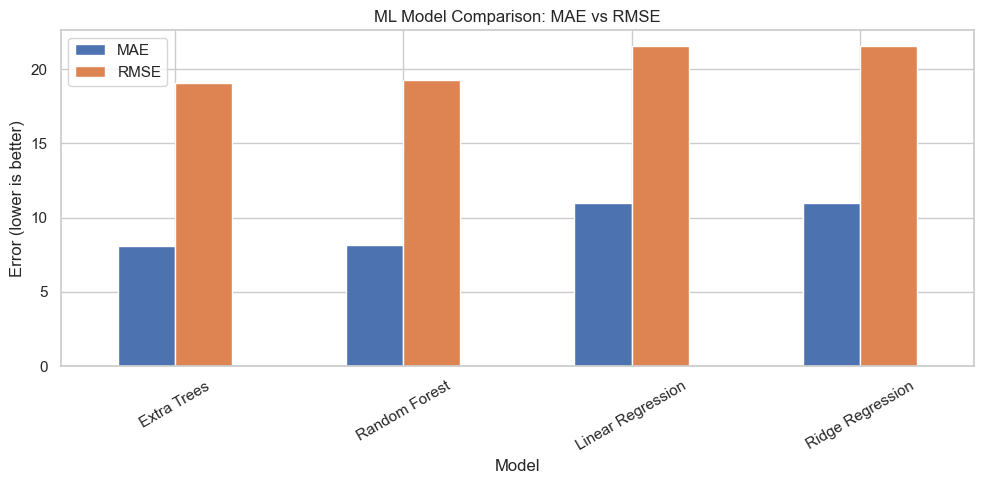

In [19]:
plot_df = results_df.set_index("Model")[["MAE", "RMSE"]]

plot_df.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("ML Model Comparison: MAE vs RMSE")
plt.ylabel("Error (lower is better)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

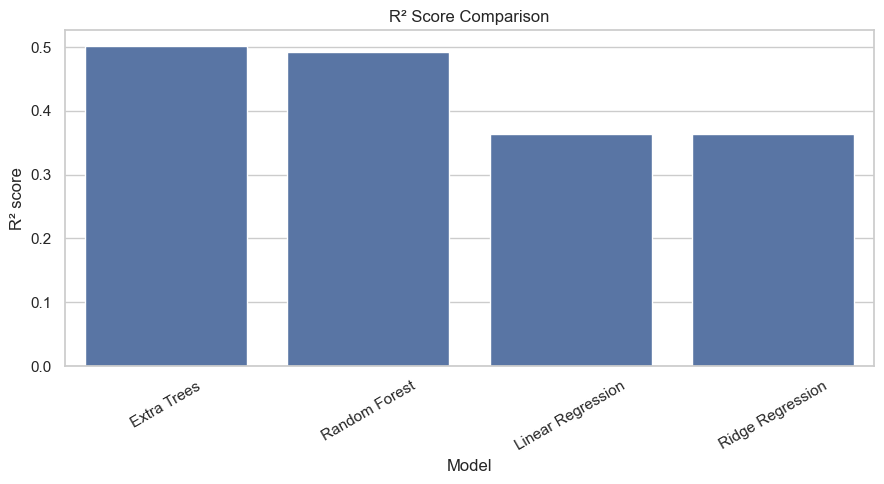

In [20]:
# Cell 17: R² comparison

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2"
)

plt.title("R² Score Comparison")
plt.ylabel("R² score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

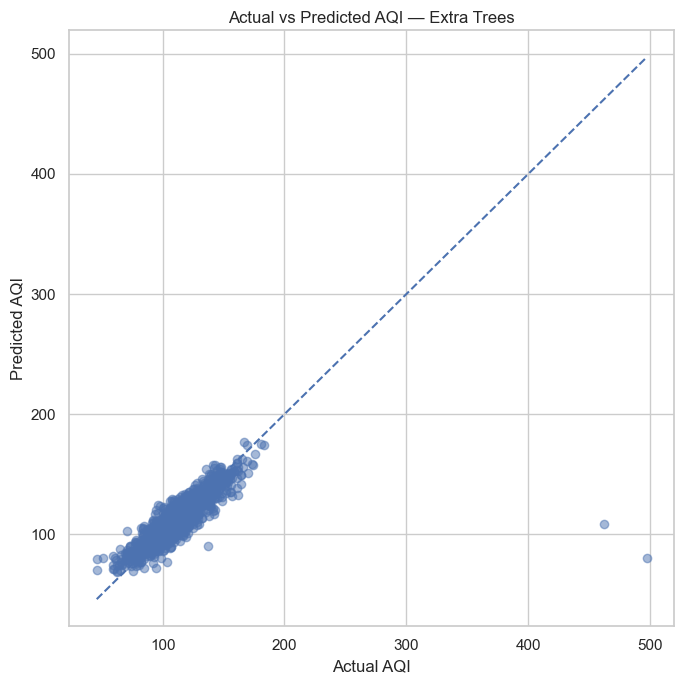

In [21]:
y_pred = best_model.predict(X_test)

plt.figure(figsize=(7, 7))

plt.scatter(y_test, y_pred, alpha=0.5)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title(f"Actual vs Predicted AQI — {best_model_name}")
plt.tight_layout()
plt.show()

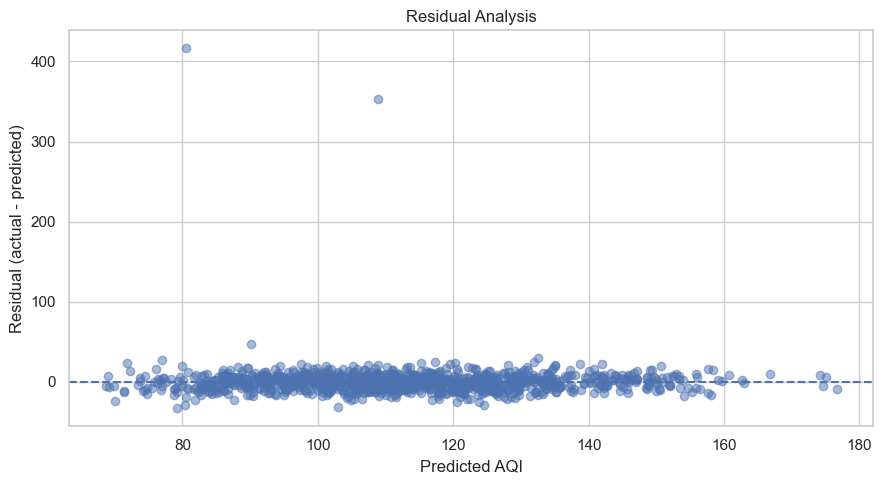

In [22]:
residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(9, 5))

plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted AQI")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residual Analysis")
plt.tight_layout()
plt.show()

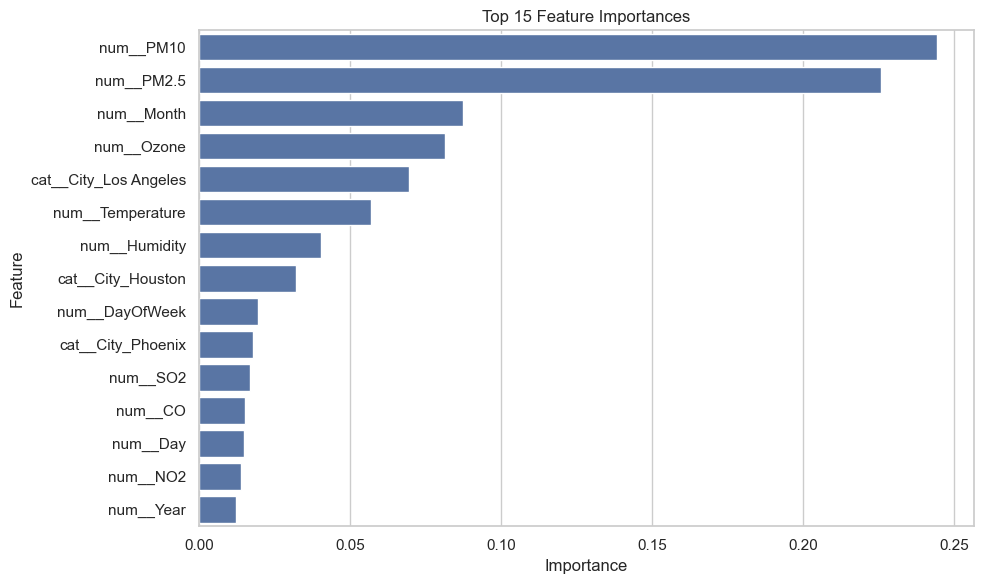

In [23]:
fitted_regressor = best_model.named_steps["model"]

if hasattr(fitted_regressor, "feature_importances_"):

    feature_names = (
        best_model.named_steps["preprocessor"]
        .get_feature_names_out()
    )

    importances = pd.DataFrame({
        "Feature": feature_names,
        "Importance": fitted_regressor.feature_importances_
    })

    importances = importances.sort_values(
        "Importance",
        ascending=False
    ).head(15)

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=importances,
        x="Importance",
        y="Feature"
    )

    plt.title("Top 15 Feature Importances")
    plt.tight_layout()
    plt.show()

else:
    print(
        "The selected model does not provide "
        "tree-based feature_importances_."
    )

In [24]:
joblib.dump(
    best_model,
    "best_aqi_model.joblib"
)

print("Saved model:", best_model_name)
print("File: best_aqi_model.joblib")

Saved model: Extra Trees
File: best_aqi_model.joblib


In [33]:
import os

print("Current folder:", os.getcwd())
print("Full file path:", os.path.abspath("best_aqi_model.joblib"))
print("File exists:", os.path.exists("best_aqi_model.joblib"))

Current folder: C:\Users\krish
Full file path: C:\Users\krish\best_aqi_model.joblib
File exists: True


In [25]:
loaded_model = joblib.load("best_aqi_model.joblib")

print("Model loaded successfully.")

Model loaded successfully.


In [26]:
def classify_aqi(aqi):

    if aqi <= 50:
        return "Good"

    elif aqi <= 100:
        return "Moderate"

    elif aqi <= 150:
        return "Unhealthy for Sensitive Groups"

    elif aqi <= 200:
        return "Unhealthy"

    elif aqi <= 300:
        return "Very Unhealthy"

    else:
        return "Hazardous"

In [1]:
def generate_alert(aqi, city):

    category = classify_aqi(aqi)

    if category == "Good":
        message = (
            f" Air Quality Update for {city}\n"
            f"Predicted AQI: {aqi:.0f}\n"
            f"Category: {category}\n\n"
            "Good air quality! Enjoy your outdoor "
            "activities and stay active."
        )

    elif category == "Moderate":
        message = (
            f" Air Quality Update for {city}\n"
            f"Predicted AQI: {aqi:.0f}\n"
            f"Category: {category}\n\n"
            "Air quality is acceptable for most people. "
            "Unusually sensitive individuals should consider "
            "reducing prolonged or strenuous outdoor activity."
        )

    elif category == "Unhealthy for Sensitive Groups":
        message = (
            f"Air Quality Alert for {city}\n"
            f"Predicted AQI: {aqi:.0f}\n"
            f"Category: {category}\n\n"
            "Sensitive individuals, including people with "
            "asthma or heart or lung conditions, should "
            "reduce prolonged outdoor exertion."
        )

    elif category == "Unhealthy":
        message = (
            f" Air Quality Warning for {city}\n"
            f"Predicted AQI: {aqi:.0f}\n"
            f"Category: {category}\n\n"
            "Reduce prolonged outdoor activity. Choose "
            "cleaner indoor air where possible and follow "
            "official health advisories."
        )

    elif category == "Very Unhealthy":
        message = (
            f" Serious Air Quality Alert for {city}\n"
            f"Predicted AQI: {aqi:.0f}\n"
            f"Category: {category}\n\n"
            "Avoid strenuous outdoor activities and reduce "
            "exposure to polluted air. Follow local health "
            "guidance."
        )

    else:
        message = (
            f"Hazardous Air Quality Alert for {city}\n"
            f"Predicted AQI: {aqi:.0f}\n"
            f"Category: {category}\n\n"
            "Avoid outdoor exposure where possible, keep "
            "indoor air cleaner, and follow official public "
            "health instructions."
        )

    return category, message

In [28]:
test_aqi_values = [35, 85, 125, 185, 250, 350]

for aqi in test_aqi_values:

    category, message = generate_alert(
        aqi=aqi,
        city="Los Angeles"
    )

    print("=" * 60)
    print("Category:", category)
    print(message)

Category: Good
 Air Quality Update for Los Angeles
Predicted AQI: 35
Category: Good

Good air quality! Enjoy your outdoor activities and stay active.
Category: Moderate
 Air Quality Update for Los Angeles
Predicted AQI: 85
Category: Moderate

Air quality is acceptable for most people. Unusually sensitive individuals should consider reducing prolonged or strenuous outdoor activity.
Category: Unhealthy for Sensitive Groups
Air Quality Alert for Los Angeles
Predicted AQI: 125
Category: Unhealthy for Sensitive Groups

Sensitive individuals, including people with asthma or heart or lung conditions, should reduce prolonged outdoor exertion.
Category: Unhealthy
 Air Quality Warning for Los Angeles
Predicted AQI: 185
Category: Unhealthy

Reduce prolonged outdoor activity. Choose cleaner indoor air where possible and follow official health advisories.
Category: Very Unhealthy
 Serious Air Quality Alert for Los Angeles
Predicted AQI: 250
Category: Very Unhealthy

Avoid strenuous outdoor activiti

In [29]:
sample = X_test.iloc[[0]].copy()
print(sample)
predicted_aqi = float(
    loaded_model.predict(sample)[0]
)

# AQI cannot be negative
predicted_aqi = max(0, predicted_aqi)

city = str(sample["City"].iloc[0])

category, message = generate_alert(
    predicted_aqi,
    city
)

print("City:", city)
print("Predicted AQI:", round(predicted_aqi, 2))
print("Category:", category)
print("\nGenerated message:\n")
print(message)
print(sample)

              City  PM2.5   PM10  Ozone    NO2    CO   SO2  Temperature  \
2525  Philadelphia  27.62  51.56   62.7  49.45  2.37  20.4          4.7   

      Humidity  Year  Month  Day  DayOfWeek  
2525      79.8  2023     12   14          3  
City: Philadelphia
Predicted AQI: 111.83
Category: Unhealthy for Sensitive Groups

Generated message:

Air Quality Alert for Philadelphia
Predicted AQI: 112
Category: Unhealthy for Sensitive Groups

Sensitive individuals, including people with asthma or heart or lung conditions, should reduce prolonged outdoor exertion.
              City  PM2.5   PM10  Ozone    NO2    CO   SO2  Temperature  \
2525  Philadelphia  27.62  51.56   62.7  49.45  2.37  20.4          4.7   

      Humidity  Year  Month  Day  DayOfWeek  
2525      79.8  2023     12   14          3  
